<a href="https://colab.research.google.com/github/yeminaung-web/AI_STUDY/blob/main/UCI_HAR/UCI_HAR(CNN%2CTransformer%2CSE_ResNet).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-

"""
UCI-HAR Classification using CNN + LSTM
TensorFlow / Keras

Input:
    UCI-HAR Inertial Signals
    Shape = (samples, 128, 9)

Channels:
    body_acc_x
    body_acc_y
    body_acc_z
    body_gyro_x
    body_gyro_y
    body_gyro_z
    total_acc_x
    total_acc_y
    total_acc_z

Classes:
    0: WALKING
    1: WALKING_UPSTAIRS
    2: WALKING_DOWNSTAIRS
    3: SITTING
    4: STANDING
    5: LAYING
"""


'\nUCI-HAR Classification using CNN + LSTM\nTensorFlow / Keras\n\nInput:\n    UCI-HAR Inertial Signals\n    Shape = (samples, 128, 9)\n\nChannels:\n    body_acc_x\n    body_acc_y\n    body_acc_z\n    body_gyro_x\n    body_gyro_y\n    body_gyro_z\n    total_acc_x\n    total_acc_y\n    total_acc_z\n\nClasses:\n    0: WALKING\n    1: WALKING_UPSTAIRS\n    2: WALKING_DOWNSTAIRS\n    3: SITTING\n    4: STANDING\n    5: LAYING\n'

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:

# ============================================================
# 1. CONFIGURATION
# ============================================================

DATASET_PATH = "/content/drive/MyDrive/Colab Notebooks/human+activity+recognition+using+smartphones/UCI HAR Dataset"

SEED = 42
VALIDATION_RATIO = 0.20

BATCH_SIZE = 64
EPOCHS = 100
LEARNING_RATE = 0.001

MODEL_PATH = "best_se_resnet_transformer_uci_har.keras"





In [5]:

# ============================================================
# 2. IMPORT LIBRARIES
# ============================================================

import os
import random
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from tensorflow.keras.models import Sequential

from tensorflow.keras.models import Model

from tensorflow.keras.layers import (
    Input,
    Conv1D,
    MaxPooling1D,
    BatchNormalization,
    Dense,
    Dropout,
    Activation,
    GlobalAveragePooling1D,
    Reshape,
    Multiply,
    Add,
    MultiHeadAttention,
    LayerNormalization
)



from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)



In [6]:

# ============================================================
# 3. RANDOM SEED
# ============================================================

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)


print("=" * 70)
print("TensorFlow version:", tf.__version__)
print("=" * 70)



TensorFlow version: 2.21.0


In [7]:

# ============================================================
# 4. SIGNAL / CLASS NAMES
# ============================================================

SIGNAL_NAMES = [
    "body_acc_x",
    "body_acc_y",
    "body_acc_z",

    "body_gyro_x",
    "body_gyro_y",
    "body_gyro_z",

    "total_acc_x",
    "total_acc_y",
    "total_acc_z"
]


CLASS_NAMES = [
    "WALKING",
    "WALKING_UPSTAIRS",
    "WALKING_DOWNSTAIRS",
    "SITTING",
    "STANDING",
    "LAYING"
]



In [8]:

# ============================================================
# 5. LOAD INERTIAL SIGNALS
# ============================================================

def load_inertial_signals(dataset_path, split):

    """
    Load 9-channel UCI-HAR inertial signals.

    Each signal file:
        shape = (N, 128)

    After stacking:
        shape = (N, 128, 9)
    """

    signal_folder = os.path.join(
        dataset_path,
        split,
        "Inertial Signals"
    )

    signals = []

    for signal_name in SIGNAL_NAMES:

        filename = f"{signal_name}_{split}.txt"

        file_path = os.path.join(
            signal_folder,
            filename
        )

        if not os.path.exists(file_path):
            raise FileNotFoundError(
                f"File not found: {file_path}"
            )

        signal = np.loadtxt(
            file_path,
            dtype=np.float32
        )

        print(
            f"{split:5s} | "
            f"{signal_name:20s} | "
            f"{signal.shape}"
        )

        signals.append(signal)

    # (N, 128, 9)
    X = np.stack(
        signals,
        axis=-1
    )

    return X


In [9]:


# ============================================================
# 6. LOAD LABELS
# ============================================================

def load_labels(dataset_path, split):

    label_path = os.path.join(
        dataset_path,
        split,
        f"y_{split}.txt"
    )

    y = np.loadtxt(
        label_path,
        dtype=np.int32
    )

    # Original UCI-HAR labels:
    # 1 ~ 6
    #
    # TensorFlow:
    # 0 ~ 5

    y = y - 1

    return y



In [10]:

# ============================================================
# 7. LOAD TRAIN / TEST DATA
# ============================================================

print("\nLoading training data...\n")

X_train_full = load_inertial_signals(
    DATASET_PATH,
    "train"
)

y_train_full = load_labels(
    DATASET_PATH,
    "train"
)


print("\nLoading test data...\n")

X_test = load_inertial_signals(
    DATASET_PATH,
    "test"
)

y_test = load_labels(
    DATASET_PATH,
    "test"
)


print("\n" + "=" * 70)
print("Original dataset")
print("=" * 70)

print(
    "X_train_full:",
    X_train_full.shape
)

print(
    "y_train_full:",
    y_train_full.shape
)

print(
    "X_test:",
    X_test.shape
)

print(
    "y_test:",
    y_test.shape
)




Loading training data...

train | body_acc_x           | (7352, 128)
train | body_acc_y           | (7352, 128)
train | body_acc_z           | (7352, 128)
train | body_gyro_x          | (7352, 128)
train | body_gyro_y          | (7352, 128)
train | body_gyro_z          | (7352, 128)
train | total_acc_x          | (7352, 128)
train | total_acc_y          | (7352, 128)
train | total_acc_z          | (7352, 128)

Loading test data...

test  | body_acc_x           | (2947, 128)
test  | body_acc_y           | (2947, 128)
test  | body_acc_z           | (2947, 128)
test  | body_gyro_x          | (2947, 128)
test  | body_gyro_y          | (2947, 128)
test  | body_gyro_z          | (2947, 128)
test  | total_acc_x          | (2947, 128)
test  | total_acc_y          | (2947, 128)
test  | total_acc_z          | (2947, 128)

Original dataset
X_train_full: (7352, 128, 9)
y_train_full: (7352,)
X_test: (2947, 128, 9)
y_test: (2947,)


In [11]:

# ============================================================
# 8. TRAIN / VALIDATION SPLIT
# ============================================================

X_train, X_val, y_train, y_val = train_test_split(

    X_train_full,
    y_train_full,

    test_size=VALIDATION_RATIO,

    random_state=SEED,

    stratify=y_train_full
)


print("\n" + "=" * 70)
print("Dataset split")
print("=" * 70)

print(
    "Train:",
    X_train.shape
)

print(
    "Validation:",
    X_val.shape
)

print(
    "Test:",
    X_test.shape
)




Dataset split
Train: (5881, 128, 9)
Validation: (1471, 128, 9)
Test: (2947, 128, 9)


In [12]:

# ============================================================
# 9. STANDARD SCALER
# ============================================================

"""
Original shape:

    (samples, 128, 9)

StandardScaler requires:

    (observations, features)

Therefore reshape:

    (samples * 128, 9)

The 9 sensor channels are standardized independently.

IMPORTANT:
    scaler.fit() is performed ONLY on training data.
"""


num_channels = X_train.shape[-1]

scaler = StandardScaler()


# ------------------------------------------------------------
# Fit scaler using training data only
# ------------------------------------------------------------

X_train_2d = X_train.reshape(
    -1,
    num_channels
)

scaler.fit(
    X_train_2d
)


# ------------------------------------------------------------
# Transform function
# ------------------------------------------------------------

def standardize_data(X, scaler):

    original_shape = X.shape

    X_2d = X.reshape(
        -1,
        original_shape[-1]
    )

    X_scaled = scaler.transform(
        X_2d
    )

    X_scaled = X_scaled.reshape(
        original_shape
    )

    return X_scaled.astype(
        np.float32
    )


# ------------------------------------------------------------
# Apply StandardScaler
# ------------------------------------------------------------

X_train = standardize_data(
    X_train,
    scaler
)

X_val = standardize_data(
    X_val,
    scaler
)

X_test = standardize_data(
    X_test,
    scaler
)


print("\n" + "=" * 70)
print("StandardScaler")
print("=" * 70)

print(
    "Training channel means:"
)

print(
    np.round(
        np.mean(
            X_train,
            axis=(0, 1)
        ),
        4
    )
)

print(
    "\nTraining channel standard deviations:"
)

print(
    np.round(
        np.std(
            X_train,
            axis=(0, 1)
        ),
        4
    )
)




StandardScaler
Training channel means:
[ 0.  0.  0.  0.  0. -0.  0. -0.  0.]

Training channel standard deviations:
[0.9997 0.9995 0.9994 0.9997 0.9996 0.9996 0.9997 0.9998 0.9998]


In [13]:
def se_resnet_block(x, filters, kernel_size=5, reduction=8):
    shortcut = x

    # ResNet Main Conv Path
    out = Conv1D(filters=filters, kernel_size=kernel_size, padding="same", use_bias=False)(x)
    out = BatchNormalization()(out)
    out = Activation("relu")(out)

    out = Conv1D(filters=filters, kernel_size=kernel_size, padding="same", use_bias=False)(out)
    out = BatchNormalization()(out)

    # Squeeze-and-Excitation (SE) Channel Attention
    se = GlobalAveragePooling1D()(out)
    se = Dense(filters // reduction, activation="relu")(se)
    se = Dense(filters, activation="sigmoid")(se)
    se = Reshape((1, filters))(se)
    out = Multiply()([out, se])

    # ResNet Skip Connection
    if shortcut.shape[-1] != filters:
        shortcut = Conv1D(filters=filters, kernel_size=1, padding="same", use_bias=False)(shortcut)
        shortcut = BatchNormalization()(shortcut)

    out = Add()([out, shortcut])
    out = Activation("relu")(out)
    return out


def transformer_encoder_block(x, d_model=128, num_heads=4, ff_dim=128, dropout=0.30):
    # Positional Encoding (zero-padded 1D conv encodes sequence order cleanly)
    pos = Conv1D(filters=d_model, kernel_size=3, padding="same")(x)
    x = Add()([x, pos])

    # Multi-Head Self-Attention + Residual
    attn_in = LayerNormalization(epsilon=1e-6)(x)
    attn_out = MultiHeadAttention(
        num_heads=num_heads,
        key_dim=d_model // num_heads,
        dropout=dropout
    )(attn_in, attn_in)
    attn_out = Dropout(dropout)(attn_out)
    x = Add()([x, attn_out])

    # Feed-Forward Network + Residual
    ffn_in = LayerNormalization(epsilon=1e-6)(x)
    ffn_out = Dense(units=ff_dim, activation="relu")(ffn_in)
    ffn_out = Dropout(dropout)(ffn_out)
    ffn_out = Dense(units=d_model)(ffn_out)
    ffn_out = Dropout(dropout)(ffn_out)
    x = Add()([x, ffn_out])

    x = LayerNormalization(epsilon=1e-6)(x)
    return x


# Using SE-ResNet + Transformer Encoder
def build_model():
    inputs = Input(shape=(128, 9))

    # SE-ResNet Block 1 -> (64, 64)
    x = se_resnet_block(inputs, filters=64, kernel_size=5)
    x = MaxPooling1D(pool_size=2)(x)
    x = Dropout(0.30)(x)

    # SE-ResNet Block 2 -> (32, 128)
    x = se_resnet_block(x, filters=128, kernel_size=5)
    x = MaxPooling1D(pool_size=2)(x)
    x = Dropout(0.30)(x)

    # Transformer Encoder Core (replaces LSTM/BiLSTM)
    x = transformer_encoder_block(x, d_model=128, num_heads=4, ff_dim=128, dropout=0.30)
    x = GlobalAveragePooling1D()(x)
    x = Dropout(0.30)(x)

    # Dense Classifier (unchanged)
    x = Dense(units=64, activation="relu")(x)
    x = Dropout(0.30)(x)
    outputs = Dense(units=6, activation="softmax")(x)

    model = Model(inputs=inputs, outputs=outputs)
    return model

model = build_model()


In [14]:

# ============================================================
# 11. COMPILE
# ============================================================

optimizer = tf.keras.optimizers.Adam(
    learning_rate=LEARNING_RATE
)


model.compile(

    optimizer=optimizer,

    loss="sparse_categorical_crossentropy",

    metrics=[
        "accuracy"
    ]
)


print("\n")
model.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 128, 9)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 128, 64)   │      2,880 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 128, 64)   │        256 │ conv1d[0][0]      │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 128, 64)   │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 128, 64)   │     20,480 │ activation[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 64)   │        256 │ conv1d_1[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 64)        │          0 │ batch_normalizat… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 8)         │        520 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 64)        │        576 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 1, 64)     │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_2 (Conv1D)   │ (None, 128, 64)   │        576 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply (Multiply) │ (None, 128, 64)   │          0 │ batch_normalizat… │
│                     │                   │            │ reshape[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 64)   │        256 │ conv1d_2[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 128, 64)   │          0 │ multiply[0][0],   │
│                     │                   │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 128, 64)   │          0 │ add[0][0]         │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d       │ (None, 64, 64)    │          0 │ activation_1[0][… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 64, 64)    │          0 │ max_pooling1d[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_3 (Conv1D)   │ (None, 64, 128)   │     40,960 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 128)   │        512 │ conv1d_3[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 320,414 (1.22 MB)

 Trainable params: 319,262 (1.22 MB)

 Non-trainable params: 1,152 (4.50 KB)

In [15]:


# ============================================================
# 12. CALLBACKS
# ============================================================

callbacks = [

    EarlyStopping(

        monitor="val_loss",

        patience=15,

        restore_best_weights=True,

        verbose=1
    ),


    ReduceLROnPlateau(

        monitor="val_loss",

        factor=0.5,

        patience=5,

        min_lr=1e-6,

        verbose=1
    ),


    ModelCheckpoint(

        filepath=MODEL_PATH,

        monitor="val_loss",

        save_best_only=True,

        verbose=1
    )
]



In [16]:

# ============================================================
# 13. TRAIN
# ============================================================

print("\n" + "=" * 70)
print("Training SE-ResNet + Transformer")
print("=" * 70)


history = model.fit(

    X_train,
    y_train,

    validation_data=(
        X_val,
        y_val
    ),

    epochs=EPOCHS,

    batch_size=BATCH_SIZE,

    callbacks=callbacks,

    verbose=1
)




Training SE-ResNet + Transformer
Epoch 1/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 412ms/step - accuracy: 0.7132 - loss: 0.7417
Epoch 1: val_loss improved from None to 0.17634, saving model to best_se_resnet_transformer_uci_har.keras

Epoch 1: finished saving model to best_se_resnet_transformer_uci_har.keras
92/92 ━━━━━━━━━━━━━━━━━━━━ 51s 449ms/step - accuracy: 0.8310 - loss: 0.4440 - val_accuracy: 0.9334 - val_loss: 0.1763 - learning_rate: 0.0010
Epoch 2/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 342ms/step - accuracy: 0.9357 - loss: 0.1821
Epoch 2: val_loss did not improve from 0.17634
92/92 ━━━━━━━━━━━━━━━━━━━━ 78s 400ms/step - accuracy: 0.9337 - loss: 0.1755 - val_accuracy: 0.9395 - val_loss: 0.1775 - learning_rate: 0.0010
Epoch 3/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 340ms/step - accuracy: 0.9450 - loss: 0.1518
Epoch 3: val_loss improved from 0.17634 to 0.11296, saving model to best_se_resnet_transformer_uci_har.keras

Epoch 3: finished saving model to best_se_resnet_transformer_uci_har.keras
92/92 ━

In [17]:

# ============================================================
# 14. LOAD BEST MODEL
# ============================================================

model = tf.keras.models.load_model(
    MODEL_PATH
)



In [18]:

# ============================================================
# 15. TEST PREDICTION
# ============================================================

test_loss, test_accuracy = model.evaluate(

    X_test,
    y_test,

    batch_size=BATCH_SIZE,

    verbose=0
)


y_prob = model.predict(

    X_test,

    batch_size=BATCH_SIZE,

    verbose=0
)


y_pred = np.argmax(
    y_prob,
    axis=1
)



In [19]:

# ============================================================
# 16. PERFORMANCE METRICS
# ============================================================

accuracy = accuracy_score(
    y_test,
    y_pred
)


macro_precision = precision_score(

    y_test,
    y_pred,

    average="macro",

    zero_division=0
)


macro_recall = recall_score(

    y_test,
    y_pred,

    average="macro",

    zero_division=0
)


macro_f1 = f1_score(

    y_test,
    y_pred,

    average="macro",

    zero_division=0
)


weighted_f1 = f1_score(

    y_test,
    y_pred,

    average="weighted",

    zero_division=0
)


print("\n" + "=" * 70)
print("TEST RESULTS")
print("=" * 70)

print(
    f"Test Loss        : {test_loss:.4f}"
)

print(
    f"Accuracy         : {accuracy:.4f}"
)

print(
    f"Macro Precision  : {macro_precision:.4f}"
)

print(
    f"Macro Recall     : {macro_recall:.4f}"
)

print(
    f"Macro F1         : {macro_f1:.4f}"
)

print(
    f"Weighted F1      : {weighted_f1:.4f}"
)




TEST RESULTS
Test Loss        : 0.5321
Accuracy         : 0.9206
Macro Precision  : 0.9219
Macro Recall     : 0.9229
Macro F1         : 0.9217
Weighted F1      : 0.9207


In [20]:

# ============================================================
# 17. CLASSIFICATION REPORT
# ============================================================

print("\n" + "=" * 70)
print("CLASSIFICATION REPORT")
print("=" * 70)


print(

    classification_report(

        y_test,
        y_pred,

        target_names=CLASS_NAMES,

        digits=4,

        zero_division=0
    )
)




CLASSIFICATION REPORT
                    precision    recall  f1-score   support

           WALKING     0.9917    0.9597    0.9754       496
  WALKING_UPSTAIRS     0.9911    0.9406    0.9651       471
WALKING_DOWNSTAIRS     0.9050    0.9976    0.9490       420
           SITTING     0.7973    0.8330    0.8147       491
          STANDING     0.8462    0.8064    0.8258       532
            LAYING     1.0000    1.0000    1.0000       537

          accuracy                         0.9206      2947
         macro avg     0.9219    0.9229    0.9217      2947
      weighted avg     0.9221    0.9206    0.9207      2947



In [21]:

# ============================================================
# 18. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_test,
    y_pred
)


print("\nConfusion Matrix")

print(cm)




Confusion Matrix
[[476   0  20   0   0   0]
 [  3 443  24   1   0   0]
 [  1   0 419   0   0   0]
 [  0   4   0 409  78   0]
 [  0   0   0 103 429   0]
 [  0   0   0   0   0 537]]


In [22]:

# ============================================================
# 19. NORMALIZED CONFUSION MATRIX
# ============================================================

cm_normalized = (

    cm.astype(np.float32)

    / np.maximum(
        cm.sum(
            axis=1,
            keepdims=True
        ),
        1
    )
)


print("\nNormalized Confusion Matrix")

print(
    np.round(
        cm_normalized,
        4
    )
)




Normalized Confusion Matrix
[[0.9597 0.     0.0403 0.     0.     0.    ]
 [0.0064 0.9406 0.051  0.0021 0.     0.    ]
 [0.0024 0.     0.9976 0.     0.     0.    ]
 [0.     0.0081 0.     0.833  0.1589 0.    ]
 [0.     0.     0.     0.1936 0.8064 0.    ]
 [0.     0.     0.     0.     0.     1.    ]]


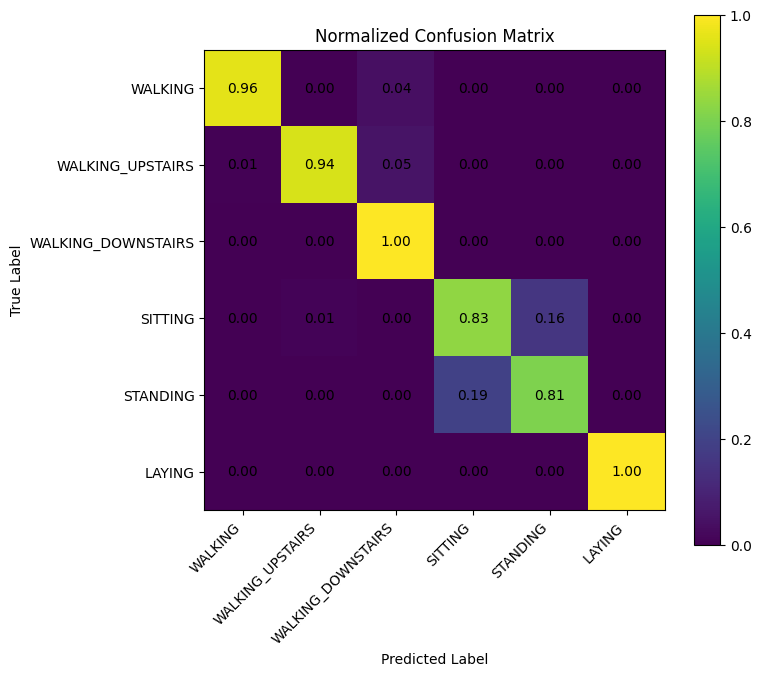

In [23]:

# ============================================================
# 20. PLOT CONFUSION MATRIX
# ============================================================

plt.figure(
    figsize=(8, 7)
)


plt.imshow(
    cm_normalized
)


plt.colorbar()


plt.xticks(

    np.arange(
        len(CLASS_NAMES)
    ),

    CLASS_NAMES,

    rotation=45,

    ha="right"
)


plt.yticks(

    np.arange(
        len(CLASS_NAMES)
    ),

    CLASS_NAMES
)


plt.xlabel(
    "Predicted Label"
)

plt.ylabel(
    "True Label"
)

plt.title(
    "Normalized Confusion Matrix"
)


for i in range(
    len(CLASS_NAMES)
):

    for j in range(
        len(CLASS_NAMES)
    ):

        plt.text(

            j,
            i,

            f"{cm_normalized[i, j]:.2f}",

            ha="center",

            va="center"
        )


plt.tight_layout()

plt.savefig(
    "confusion_matrix_se_resnet_lstm.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


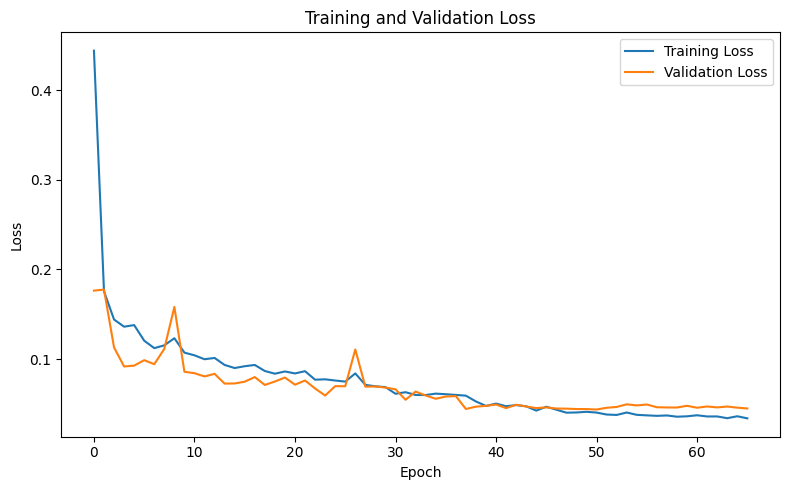

In [24]:


# ============================================================
# 21. TRAINING LOSS
# ============================================================

plt.figure(
    figsize=(8, 5)
)


plt.plot(
    history.history["loss"],
    label="Training Loss"
)


plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)


plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Loss"
)

plt.title(
    "Training and Validation Loss"
)

plt.legend()

plt.tight_layout()

plt.show()



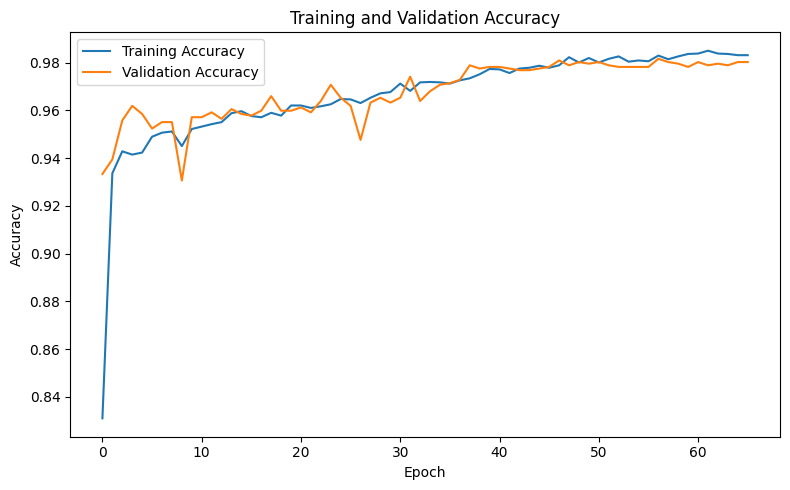


Finished.


In [25]:

# ============================================================
# 22. TRAINING ACCURACY
# ============================================================

plt.figure(
    figsize=(8, 5)
)


plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)


plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)


plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Accuracy"
)

plt.title(
    "Training and Validation Accuracy"
)

plt.legend()

plt.tight_layout()

plt.show()


print("\nFinished.")